## Импорты библиотек и считывание данных

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.inspection import permutation_importance
from metric import pr_curve, precision_at_recall, recall_at_fpr
import lightgbm as lgb
import xgboost as xgb
from catboost import CatBoostClassifier

pd.set_option('display.max_columns', None)

In [2]:
RANDON_SEED = 42
validation_start_date = pd.to_datetime('2026-04-17')

In [3]:
train = pd.read_csv('data/train.csv', parse_dates=['cookie_created_at', 'window_start_ts', 'window_end_ts'])
test = pd.read_csv('data/test.csv', parse_dates=['cookie_created_at', 'window_start_ts', 'window_end_ts'])
events = pd.read_csv('data/events.csv.gz', parse_dates=['event_ts'])

In [4]:
train.head(10)

,cookie_id,cookie_created_at,window_start_ts,window_end_ts,target
0,ck_54a059eb7d3ea68b,2025-11-21 09:30:41,2026-04-06,2026-04-07,0
1,ck_7e4de46eeab82974,2025-09-23 10:10:24,2026-04-06,2026-04-07,0
2,ck_9320229ef6304522,2026-03-04 00:08:02,2026-04-06,2026-04-07,0
3,ck_30ccd25bc1714ed9,2026-04-05 10:52:40,2026-04-06,2026-04-07,0
4,ck_a77c5f05948cdeef,2026-01-01 03:54:35,2026-04-06,2026-04-07,0
5,ck_ea6f843af2292fec,2026-02-28 17:39:05,2026-04-06,2026-04-07,0
6,ck_e38634dc2f188574,2025-11-02 16:17:05,2026-04-06,2026-04-07,0
7,ck_ad7f01440bb250d1,2026-04-05 15:53:42,2026-04-06,2026-04-07,0
8,ck_a7a58d28a4482bdc,2025-08-05 13:31:50,2026-04-06,2026-04-07,0
9,ck_e00e1e6c2a2ab4ac,2026-01-19 06:46:34,2026-04-06,2026-04-07,1


In [5]:
train['target'].value_counts()

target
0    10192
1      899
Name: count, dtype: int64

In [6]:
test.head(1)

,cookie_id,cookie_created_at,window_start_ts,window_end_ts
0,ck_315fb710a0e371e7,2026-02-20 08:52:31,2026-04-20,2026-04-21


In [7]:
test.tail(3)

,cookie_id,cookie_created_at,window_start_ts,window_end_ts
4906,ck_3e6833574edf1736,2026-02-06 19:45:02,2026-04-26,2026-04-27
4907,ck_e527fbb9450a4581,2026-04-25 17:28:41,2026-04-26,2026-04-27
4908,ck_cc90e219f1ebf390,2025-08-09 06:12:48,2026-04-26,2026-04-27


In [8]:
events.head()

,cookie_id,event_ts,eid,event_name,platform,user_agent,item_id,item_category,item_location,seller_type,search_query,search_page,pointer_x,pointer_y
0,ck_5efbea1befdefe1b,2026-04-26 09:11:24,200,item_view,desktop,Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7...,1027450.0,elektronika,kaliningrad,pro,NaN,NaN,NaN,NaN
1,ck_c4ca1434f3778f1d,2026-04-20 14:04:31,100,search_results_view,web,Mozilla/5.0 (Windows NT 10.0; Win64; x64; rv:1...,NaN,telefony,habarovsk,NaN,iphone 13 128,4.0,NaN,NaN
2,ck_d274382b19488771,2026-04-13 12:02:56,200,item_view,WEB,Mozilla/5.0 (Windows NT 10.0; Win64; x64) Appl...,1048743.0,kvartiry_prodazha,kirov,private,NaN,NaN,675.0,276.0
3,ck_fbbed2ff14944ce9,2026-04-08 06:12:14,100,search_results_view,web,Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7...,NaN,bytovaya_tehnika,novosibirsk,NaN,пылесос dyson,2.0,NaN,NaN
4,ck_56cc15c7c634cb9f,2026-04-12 17:16:05,100,search_results_view,WEB,Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7...,NaN,odezhda,sankt-peterburg,NaN,костюм мужской,2.0,NaN,NaN


In [9]:
events.event_name.value_counts()

event_name
item_view               120817
search_results_view     100402
photo_swipe              36517
favorite_add             19049
seller_page_view         17403
contact_phone_show       11316
captcha_shown             7928
login                     6267
contact_chat_open         6125
contact_message_sent      3081
Name: count, dtype: int64

In [10]:
events.platform.value_counts()

platform
desktop    46866
WEB        46476
Web        46365
web        45951
ANDROID    42462
Android    42254
android    42159
iphone      4103
IOS         4100
iOS         4091
ios         4078
Name: count, dtype: int64

In [11]:
def map_platform(platform):
    if platform == 'desktop':
        return 'desktop'
    elif platform in ['android', 'iphone', 'ios']:
        return 'smartphone'
    elif platform == 'web':
        return 'web'
    else:
        return 'unknown'

events['platform_grouped'] = events['platform'].str.lower().apply(map_platform)

In [12]:
events['user_agent'].value_counts()

user_agent
Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/119.0.0.0 YaBrowser/23.11.0.0 Safari/537.36    3737
Mozilla/5.0 (Windows NT 10.0; Win64; x64; rv:119.0) Gecko/20100101 Firefox/119.0                                                       3670
Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/117.0.0.0 YaBrowser/23.9.0.0 Safari/537.36     3664
Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0.0.0 YaBrowser/23.0.0.0 Safari/537.36     3640
Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/123.0.0.0 YaBrowser/23.3.0.0 Safari/537.36     3558
                                                                                                                                       ... 
Go-http-client/1.1                                                                                                                     1196
python-ur

In [13]:
events['item_category'].value_counts()

item_category
avtomobili           20822
mebel                20541
bytovaya_tehnika     20161
hobbi                20020
elektronika          20002
uslugi               19869
odezhda              19846
kvartiry_arenda      19713
kvartiry_prodazha    19709
noutbuki             19583
detskie_tovary       19441
rabota               19387
telefony             19349
zhivotnye            19109
zapchasti            18433
Name: count, dtype: int64

In [14]:
events['hour'] = events['event_ts'].dt.hour

def time_of_day(h):
    if 0 <= h < 6: return 'night'
    elif 6 <= h < 12: return 'morning'
    elif 12 <= h < 18: return 'day'
    else: return 'evening'

events['time_of_day'] = events['hour'].apply(time_of_day)

In [15]:
events = events.drop_duplicates()

## Разработка нового датафрейма для обучения

In [16]:
def events_in_window(events, meta):
    ev = events.merge(
        meta[['cookie_id', 'window_start_ts', 'window_end_ts']],
        on='cookie_id'
    )
    return ev[
        (ev.event_ts >= ev.window_start_ts) &
        (ev.event_ts < ev.window_end_ts)
    ]

In [17]:
def enhanced_features(ev, meta):
    """
    Функция создает признаки для детекции ботов на уровне пользователей.
    На вход принимает события (ev) и метаданные (meta),
    на выходе возвращает DataFrame с одной строкой на пользователя.
    """
    ev = ev.copy()
    ev['event_ts'] = pd.to_datetime(ev['event_ts'])

    # Сортируем по пользователю и времени
    ev = ev.sort_values(['cookie_id', 'event_ts'])

    # Интервалы между событиями: у ботов они равномерные, у людей +- хаотичные
    ev['time_diff'] = ev.groupby('cookie_id')['event_ts'].diff().dt.total_seconds()
    ev['hour'] = ev['event_ts'].dt.hour
    ev['dayofweek'] = ev['event_ts'].dt.dayofweek

    # Определяем мобильные устройства - у них нет данных курсора
    ev['platform_lower'] = ev['platform'].astype(str).str.lower()
    ev['is_mobile'] = ev['platform_lower'].isin(['android', 'ios', 'iphone']).astype(int)

    # Анализируем строку User-Agent для выявления явных ботов
    ev['ua_str'] = ev['user_agent'].astype(str)
    ev['ua_length'] = ev['ua_str'].str.len()

    # Ищем явные признаки ботов в User-Agent (python-requests, curl и т.д.)
    ev['is_bot_ua'] = ev['ua_str'].str.contains(
        r'python|urllib|requests|go-http|curl|wget|bot|crawler|spider|headless|selenium|phantom',
        case=False, regex=True
    ).astype(int)

    # Классифицируем браузеры для анализа разнообразия
    def get_browser(ua):
        ua = ua.lower()
        if 'yabrowser' in ua: return 'yabrowser'
        if 'chrome' in ua and 'mobile' in ua: return 'chrome_mobile'
        if 'chrome' in ua: return 'chrome'
        if 'firefox' in ua: return 'firefox'
        if 'safari' in ua: return 'safari'
        if 'python' in ua or 'urllib' in ua or 'requests' in ua: return 'python'
        if 'go-http' in ua: return 'go_http'
        if 'curl' in ua or 'wget' in ua: return 'curl'
        return 'other'

    ev['browser'] = ev['ua_str'].apply(get_browser)

    ev['search_query_len'] = ev['search_query'].astype(str).str.len()

    g = ev.groupby('cookie_id')

    features = pd.DataFrame(index=g.groups.keys())
    features.index.name = 'cookie_id'

    features['n_events'] = g.size()

    # Коэффициент вариации (cv) у ботов близок к 0 (равномерные интервалы), у людей больше
    features['time_diff_mean'] = g['time_diff'].mean()
    features['time_diff_std'] = g['time_diff'].std()
    features['time_diff_cv'] = features['time_diff_std'] / (features['time_diff_mean'] + 1e-6)
    features['time_diff_min'] = g['time_diff'].min()
    features['time_diff_max'] = g['time_diff'].max()
    features['time_diff_median'] = g['time_diff'].median()
    features['n_unique_time_diffs'] = g['time_diff'].nunique()

    # Активность по часам, боты часто работают круглосуточно равномерно
    features['hour_mean'] = g['hour'].mean()
    features['hour_std'] = g['hour'].std()
    features['unique_hours'] = g['hour'].nunique()

    # Люди совершают разные действия
    features['n_unique_event_types'] = g['eid'].nunique()

    # Боты могут просматривать мало уникальных объявлений
    features['item_nunique'] = g['item_id'].nunique()
    features['category_nunique'] = g['item_category'].nunique()
    features['location_nunique'] = g['item_location'].nunique()
    features['seller_type_nunique'] = g['seller_type'].nunique()

    # Сколько раз в среднем смотрят одно объявление
    features['views_per_item'] = features['n_events'] / (features['item_nunique'] + 1)

    # У людей может меняться браузер, у ботов обычно один
    features['n_unique_ua'] = g['ua_str'].nunique()
    features['has_bot_ua'] = g['is_bot_ua'].max()
    features['bot_ua_ratio'] = g['is_bot_ua'].mean()
    features['ua_length_std'] = g['ua_length'].std()
    features['ua_length_mean'] = g['ua_length'].mean()
    features['n_unique_browsers'] = g['browser'].nunique()

    features['n_unique_platforms'] = g['platform_lower'].nunique()
    features['is_mobile_ratio'] = g['is_mobile'].mean()

    # Работает только с событиями, где есть координаты курсора
    # У ботов курсор либо неподвижен, либо движется неестественно
    ev_with_ptr = ev.dropna(subset=['pointer_x', 'pointer_y'])
    if len(ev_with_ptr) > 0:
        g_ptr = ev_with_ptr.groupby('cookie_id')
        features['pointer_n_events'] = g_ptr.size()
        features['pointer_std_x'] = g_ptr['pointer_x'].std()
        features['pointer_std_y'] = g_ptr['pointer_y'].std()
        features['pointer_range_x'] = g_ptr['pointer_x'].max() - g_ptr['pointer_x'].min()
        features['pointer_range_y'] = g_ptr['pointer_y'].max() - g_ptr['pointer_y'].min()
        features['pointer_unique_x'] = g_ptr['pointer_x'].nunique()

    # Поисковые запросы
    ev_with_search = ev.dropna(subset=['search_query'])
    if len(ev_with_search) > 0:
        g_search = ev_with_search.groupby('cookie_id')
        features['search_nunique'] = g_search['search_query'].nunique()
        features['search_query_mean_len'] = g_search['search_query_len'].mean()
        features['max_search_page'] = g_search['search_page'].max()

    features = features.reset_index()
    features = meta[['cookie_id']].merge(features, on='cookie_id', how='left')

    count_cols = [
        'n_events', 'item_nunique', 'category_nunique', 'location_nunique',
        'seller_type_nunique', 'n_unique_event_types', 'n_unique_ua',
        'n_unique_platforms', 'n_unique_time_diffs', 'unique_hours',
        'n_unique_browsers', 'pointer_n_events', 'search_nunique'
    ]
    for col in count_cols:
        if col in features.columns:
            features[col] = features[col].fillna(0)

    # Флаги наличия данных
    features['has_pointer'] = (features['pointer_n_events'] > 0).astype(int)
    features['has_search'] = (features['search_nunique'] > 0).astype(int)

    return features

In [18]:
ev_tr = events_in_window(events, train)
ev_te = events_in_window(events, test)
Xtr = enhanced_features(ev_tr, train)
Xte = enhanced_features(ev_te, test)
df = train.merge(Xtr, on='cookie_id', how='left')
X_test = test.merge(Xte, on='cookie_id', how='left')

In [19]:
df.head()

,cookie_id,cookie_created_at,window_start_ts,window_end_ts,target,n_events,time_diff_mean,time_diff_std,time_diff_cv,time_diff_min,time_diff_max,time_diff_median,n_unique_time_diffs,hour_mean,hour_std,unique_hours,n_unique_event_types,item_nunique,category_nunique,location_nunique,seller_type_nunique,views_per_item,n_unique_ua,has_bot_ua,bot_ua_ratio,ua_length_std,ua_length_mean,n_unique_browsers,n_unique_platforms,is_mobile_ratio,pointer_n_events,pointer_std_x,pointer_std_y,pointer_range_x,pointer_range_y,pointer_unique_x,search_nunique,search_query_mean_len,max_search_page,has_pointer,has_search
0,ck_54a059eb7d3ea68b,2025-11-21 09:30:41,2026-04-06,2026-04-07,0,7,27.833333,29.949402,1.076026,1.0,84.0,21.0,6,1.000000,0.000000,1,3,4,3,5,2,1.400000,1,0,0.0,0.0,48.0,1,1,1.0,0.0,NaN,NaN,NaN,NaN,NaN,3.0,16.000000,6.0,0,1
1,ck_7e4de46eeab82974,2025-09-23 10:10:24,2026-04-06,2026-04-07,0,41,986.900000,2416.286861,2.448360,2.0,8511.0,57.5,36,14.829268,4.024316,8,7,19,1,12,2,2.050000,1,0,0.0,0.0,130.0,1,2,0.0,38.0,509.231969,272.953569,1905.0,949.0,36.0,5.0,18.125000,8.0,1,1
2,ck_9320229ef6304522,2026-03-04 00:08:02,2026-04-06,2026-04-07,0,36,1042.600000,2306.449400,2.212209,1.0,8350.0,22.0,27,5.777778,3.906852,7,9,19,7,9,2,1.800000,1,0,0.0,0.0,111.0,1,2,0.0,35.0,602.124295,312.027426,1869.0,1035.0,35.0,10.0,14.230769,10.0,1,1
3,ck_30ccd25bc1714ed9,2026-04-05 10:52:40,2026-04-06,2026-04-07,0,21,861.050000,2502.081501,2.905849,6.0,8604.0,54.5,18,4.666667,2.373464,3,5,10,1,4,2,1.909091,1,0,0.0,0.0,111.0,1,2,0.0,0.0,NaN,NaN,NaN,NaN,NaN,3.0,14.333333,2.0,0,1
4,ck_a77c5f05948cdeef,2026-01-01 03:54:35,2026-04-06,2026-04-07,0,28,707.333333,1748.439172,2.471874,22.0,7224.0,52.0,26,11.107143,1.617938,5,6,16,4,6,2,1.647059,1,0,0.0,0.0,117.0,1,2,0.0,27.0,450.561957,295.966031,1761.0,1036.0,27.0,6.0,15.000000,7.0,1,1


In [20]:
df_0 = df[df['target'] == 0]
df_1 = df[df['target'] == 1]

In [21]:
X_train = df[df['window_start_ts'] < validation_start_date].drop(columns=['cookie_id', 'cookie_created_at', 'window_start_ts', 'window_end_ts', 'target', 'has_bot_ua', 'bot_ua_ratio', 'has_search'])
X_val = df[df['window_start_ts'] >= validation_start_date].drop(columns=['cookie_id', 'cookie_created_at', 'window_start_ts', 'window_end_ts', 'target', 'has_bot_ua', 'bot_ua_ratio', 'has_search'])
X = df.drop(columns=['cookie_id', 'cookie_created_at', 'window_start_ts', 'window_end_ts', 'target', 'has_bot_ua', 'bot_ua_ratio', 'has_search'])
X_test = X_test.drop(columns=['cookie_id', 'cookie_created_at', 'window_start_ts', 'window_end_ts', 'has_bot_ua', 'bot_ua_ratio', 'has_search'])

y = df['target']
y_train = df[df['window_start_ts'] < validation_start_date]['target']
y_val = df[df['window_start_ts'] >= validation_start_date]['target']

print(f"Обучающая выборка: {len(X_train)} пользователей")
print(f"Валидационная выборка: {len(X_val)} пользователей")

Обучающая выборка: 9140 пользователей
Валидационная выборка: 1951 пользователей


## Обучение модели

Я пробовала разные модели на градиентном спуске с деревьями и ансамлби моделей. Лучшая модель catboost. Также ниже после сохранения данных я оставила примеры с другими моделями, чтобы можно было оценить метрики

In [22]:
model = CatBoostClassifier(random_state=RANDON_SEED, verbose=100, auto_class_weights='Balanced')
model.fit(X_train, y_train)
y_pred = model.predict_proba(X_val)[:, 1]

Learning rate set to 0.026501
0:	learn: 0.6771264	total: 139ms	remaining: 2m 19s
100:	learn: 0.3324981	total: 520ms	remaining: 4.63s
200:	learn: 0.2787795	total: 900ms	remaining: 3.58s
300:	learn: 0.2427253	total: 1.27s	remaining: 2.96s
400:	learn: 0.2049562	total: 1.66s	remaining: 2.47s
500:	learn: 0.1709084	total: 2.09s	remaining: 2.08s
600:	learn: 0.1449469	total: 2.52s	remaining: 1.67s
700:	learn: 0.1255168	total: 2.91s	remaining: 1.24s
800:	learn: 0.1095734	total: 3.3s	remaining: 820ms
900:	learn: 0.0965231	total: 3.71s	remaining: 408ms
999:	learn: 0.0858343	total: 4.13s	remaining: 0us


## Отбор признаков

Permutation Importance использовала для отбора признаков. С помощью него выявила, что столбцы 'has_bot_ua', 'bot_ua_ratio', 'has_search' хуже влияли на модель (метрика становилась лучше при перемешивании). Эти признаки были и у target 1 и у target 0, поэтому они путали модель


Топ-15 признаков (Permutation Importance):
                  feature  importance_mean  importance_std
6        time_diff_median         0.036648        0.004197
13       category_nunique         0.030702        0.002687
14       location_nunique         0.023424        0.004742
24          pointer_std_x         0.017888        0.002309
16         views_per_item         0.013121        0.002460
4           time_diff_min         0.010815        0.002736
23       pointer_n_events         0.008867        0.001932
7     n_unique_time_diffs         0.007381        0.001975
19         ua_length_mean         0.005126        0.001761
28       pointer_unique_x         0.004767        0.001849
22        is_mobile_ratio         0.003742        0.002025
27        pointer_range_y         0.003742        0.001572
32            has_pointer         0.003383        0.001239
31        max_search_page         0.001128        0.001787
30  search_query_mean_len         0.000974        0.001596


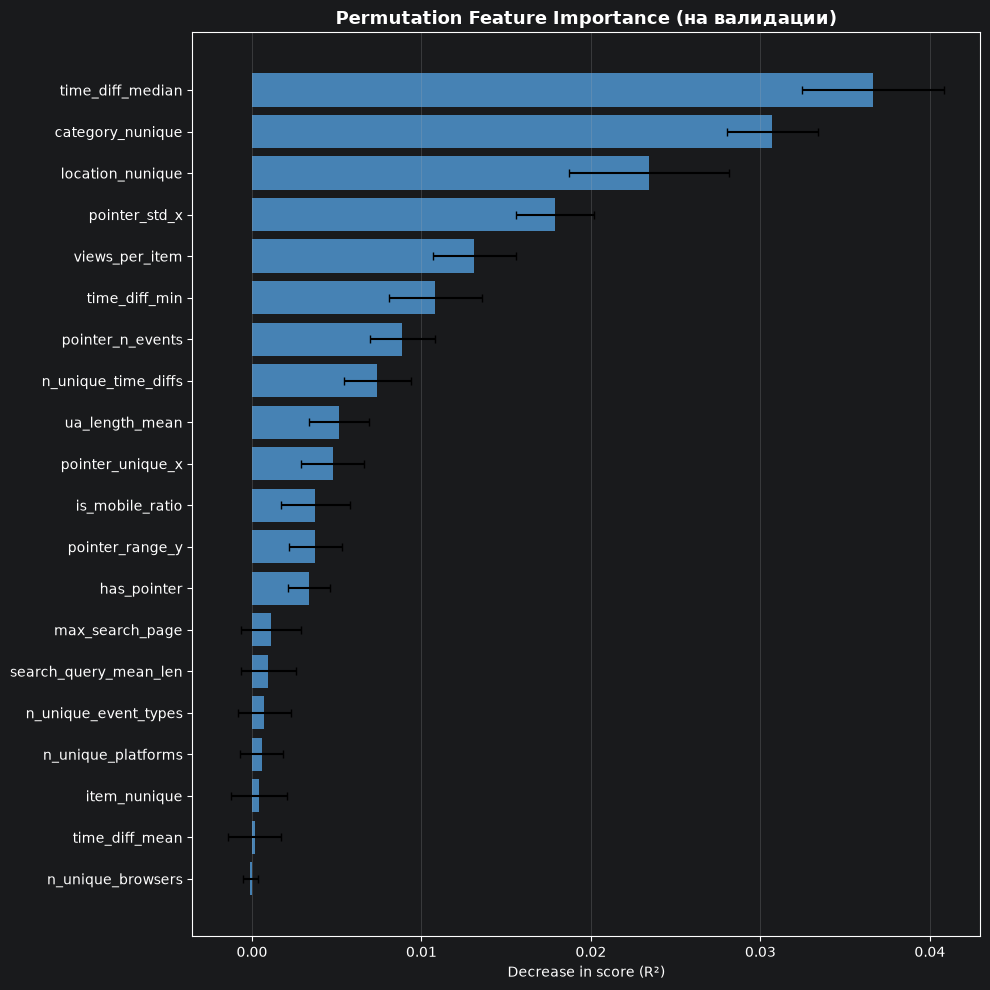

In [23]:
result = permutation_importance(
    model,
    X_val,
    y_val,
    n_repeats=10,
    n_jobs=-1
)

perm_importance = pd.DataFrame({
    'feature': X_val.columns,
    'importance_mean': result.importances_mean,
    'importance_std': result.importances_std
}).sort_values('importance_mean', ascending=False)

print("\nТоп-15 признаков (Permutation Importance):")
print(perm_importance.head(15))

plt.figure(figsize=(10, 10))
top_n = 20
top_features = perm_importance.head(top_n)

plt.barh(
    range(top_n),
    top_features['importance_mean'][::-1],
    xerr=top_features['importance_std'][::-1],
    color='steelblue',
    capsize=3
)
plt.yticks(range(top_n), top_features['feature'][::-1])
plt.xlabel('Decrease in score (R²)')
plt.title('Permutation Feature Importance (на валидации)', fontsize=13, fontweight='bold')
plt.grid(True, axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

In [24]:
print(f"Пользователей с ботным UA: {(Xtr['has_bot_ua'] > 0).sum()}")
print(f"Всего пользователей: {len(Xtr)}")
print(f"Доля: {(Xtr['has_bot_ua'] > 0).mean():.4f}")

bot_ua_bots = train[(Xtr['has_bot_ua'] > 0) & (train['target'] == 1)]
bot_ua_humans = train[(Xtr['has_bot_ua'] > 0) & (train['target'] == 0)]
print(f"Боты с ботным UA: {len(bot_ua_bots)}")
print(f"Люди с ботным UA: {len(bot_ua_humans)}")

Пользователей с ботным UA: 418
Всего пользователей: 11091
Доля: 0.0377
Боты с ботным UA: 101
Люди с ботным UA: 317


In [25]:
pr_curve(y_val, y_pred)

(array([1.        , 1.        , 1.        , ..., 0.08209338, 0.08205128,
        0.08200923], shape=(1950,)),
 array([0.00625, 0.0125 , 0.01875, ..., 1.     , 1.     , 1.     ],
       shape=(1950,)))

## Полученные метрики

In [26]:
precision_at_recall(y_val, y_pred)

0.6473988439306358

In [27]:
recall_at_fpr(y_val, y_pred)

0.55625

## Сохранение результатов

In [28]:
model.fit(X, y)
# pred = model.predict(X_test)
sub = pd.DataFrame({
    'cookie_id': Xte.cookie_id,
    'score': model.predict_proba(X_test)[:, 1],
})
assert len(sub) == len(test) and sub.score.between(0, 1).all()
sub.to_csv('submission.csv', index=False)
sub.head()

Learning rate set to 0.028783
0:	learn: 0.6758759	total: 7.62ms	remaining: 7.62s
100:	learn: 0.3307975	total: 661ms	remaining: 5.88s
200:	learn: 0.2785766	total: 1.28s	remaining: 5.11s
300:	learn: 0.2453984	total: 1.87s	remaining: 4.35s
400:	learn: 0.2101089	total: 2.48s	remaining: 3.7s
500:	learn: 0.1777844	total: 3.14s	remaining: 3.13s
600:	learn: 0.1534654	total: 3.78s	remaining: 2.51s
700:	learn: 0.1342183	total: 4.48s	remaining: 1.91s
800:	learn: 0.1176746	total: 5.15s	remaining: 1.28s
900:	learn: 0.1044986	total: 5.8s	remaining: 637ms
999:	learn: 0.0930823	total: 6.46s	remaining: 0us


,cookie_id,score
0,ck_315fb710a0e371e7,0.000384
1,ck_a76ee3b3e3e522fd,0.280133
2,ck_94c9a4d382689e82,0.144957
3,ck_8eaf9509ad9462a0,0.001880
4,ck_9a88a5a989cb5bc6,0.033727


## Остальные модели для примера с их метриками

### Ансамбль моделей Catboost и LightGBM

In [29]:
cb = CatBoostClassifier(
    iterations=500, depth=6, learning_rate=0.1,
    auto_class_weights='Balanced', random_state=RANDON_SEED, verbose=0
)
cb.fit(X_train, y_train)
p_cb = cb.predict_proba(X_val)[:, 1]

lgb_model = lgb.LGBMClassifier(
    n_estimators=500, num_leaves=63, learning_rate=0.1,
    is_unbalance=True, random_state=RANDON_SEED, verbose=-1
)
lgb_model.fit(X_train, y_train)
p_lgb = lgb_model.predict_proba(X_val)[:, 1]

cb2 = CatBoostClassifier(
    iterations=700, depth=8, learning_rate=0.05,
    auto_class_weights='Balanced', random_state=1337, verbose=0
)
cb2.fit(X_train, y_train)
p_cb2 = cb2.predict_proba(X_val)[:, 1]

y_pred = (p_cb + p_lgb + p_cb2) / 3.0

print(pr_curve(y_val, y_pred))
print(precision_at_recall(y_val, y_pred))
print(recall_at_fpr(y_val, y_pred))

(array([1.        , 1.        , 1.        , ..., 0.08209338, 0.08205128,
       0.08200923], shape=(1950,)), array([0.00625, 0.0125 , 0.01875, ..., 1.     , 1.     , 1.     ],
      shape=(1950,)))
0.710691823899371
0.6


### Модель XGBoost

In [30]:
n_neg = df_0.shape[0]
n_pos = df_1.shape[0]
scale_pos_weight = n_neg / n_pos

model_xgb = xgb.XGBClassifier(
    n_estimators=500,
    max_depth=6,
    learning_rate=0.1,
    scale_pos_weight=scale_pos_weight,
    tree_method='hist',
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=RANDON_SEED,
    n_jobs=-1,
    verbosity=0
)

model_xgb.fit(X_train, y_train)

y_pred = model_xgb.predict_proba(X_val)[:, 1]

print(pr_curve(y_val, y_pred))
print(precision_at_recall(y_val, y_pred))
print(recall_at_fpr(y_val, y_pred))

(array([1.        , 1.        , 1.        , ..., 0.08209338, 0.08205128,
       0.08200923], shape=(1950,)), array([0.00625, 0.0125 , 0.01875, ..., 1.     , 1.     , 1.     ],
      shape=(1950,)))
0.6333333333333333
0.56875


### Модель LightGBM

In [31]:
model_lgb = lgb.LGBMClassifier(
    is_unbalance=True,
    random_state=RANDON_SEED,
    verbose=-1,
    n_jobs=-1
)

model_lgb.fit(X_train, y_train)

y_pred = model_lgb.predict_proba(X_val)[:, 1]

print(pr_curve(y_val, y_pred))
print(precision_at_recall(y_val, y_pred))
print(recall_at_fpr(y_val, y_pred))

(array([1.        , 1.        , 1.        , ..., 0.08209338, 0.08205128,
       0.08200923], shape=(1945,)), array([0.00625, 0.0125 , 0.01875, ..., 1.     , 1.     , 1.     ],
      shape=(1945,)))
0.64
0.55
